# WICOS Project - Model 2: SVM with RBF Kernel on Hand-Crafted Features
In this notebook we classify the four radar hand gestures with a support vector machine (SVM, Lecture 3) on the same 27 hand-crafted features as Model 1. The RBF kernel lets the SVM draw a nonlinear decision boundary, so this model shows whether a nonlinear classifier helps compared to the linear logistic regression. For more than two classes, sklearn's `SVC` combines binary classifiers (one-versus-one).

Two hyperparameters are tuned: C (the penalty for misclassified training samples, C = 1/(2λ)) and γ (the width of the RBF kernel: a large γ gives a very flexible boundary). We also test whether feature selection with an L1 logistic regression (Lasso) helps.

The aim of the project is to recognise a gesture *regardless of the person who performs it*. The 40 samples per person and gesture are cut from one continuous recording, so samples of the same person are very similar. With a random split, the model sees the test person during training and the score is too optimistic.

All models are therefore validated with **leave-one-person-out (LOPO)** cross-validation: the model is trained on five persons and tested on the sixth, once for every person. Hyperparameters are chosen with a second LOPO loop *inside* the five training persons (nested cross-validation), so the test person is never used to choose the model.

In [1]:
# Import packages needed for the lab
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn import svm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, PredefinedSplit, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.feature_selection import SelectFromModel

C:\Users\hawma\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.stats import gaussian_kde


In [2]:
SEED = 42
np.random.seed(SEED)

# Folders for the report figures and the results
FIG_DIR = Path("../reports/figures")
RES_DIR = Path("../results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

## Task 1 - Data Preparation
- Load the prepared dataset and check the number of samples per person and gesture.

In [3]:
# Load the prepared dataset (created by src/prepare_data.py)
data = np.load("../data/processed/wicos_dataset.npz", allow_pickle=True)

X = data["X_feat"]                          # hand-crafted features, not scaled yet
y = data["y"]                               # 0=wave, 1=pinch, 2=swipe, 3=click
persons = data["persons"]                   # person who performed the gesture (A-F)
feature_names = list(data["feature_names"])
gestures = list(data["gestures"])

print("Feature matrix X: " + str(X.shape))
print("Label vector y:   " + str(y.shape))

Feature matrix X: (960, 27)
Label vector y:   (960,)


In [4]:
#Number of samples per person and gesture
pd.crosstab(persons, np.array(gestures)[y], rownames=["person"], colnames=["gesture"])

gesture,click,pinch,swipe,wave
person,,,,
A,40,40,40,40
B,40,40,40,40
C,40,40,40,40
D,40,40,40,40
E,40,40,40,40
F,40,40,40,40


The features are scaled with `StandardScaler` inside a `Pipeline`, so the scaler is fitted on the training persons only. Scaling is essential for the RBF kernel, because it is based on distances between samples.

The function `lopo_scores` computes the accuracy and macro-F1 score for every held-out person. Macro-F1 averages the F1 score of the four gestures, so every gesture counts equally. `print_scores` prints the mean ± standard deviation over the six persons.

In [5]:
def lopo_scores(y_true, y_pred, groups):
    # Accuracy and macro-F1 per held-out person
    rows = []
    for p in np.unique(groups):
        mask = groups == p
        rows.append({
            "person": p,
            "accuracy": accuracy_score(y_true[mask], y_pred[mask]),
            "f1_macro": f1_score(y_true[mask], y_pred[mask], average="macro"),
        })
    return pd.DataFrame(rows)


def print_scores(scores):
    # Mean and standard deviation over the six persons
    print("Accuracy: " + f"{scores.accuracy.mean():.3f} ± {scores.accuracy.std():.3f}")
    print("F1 score (macro): " + f"{scores.f1_macro.mean():.3f} ± {scores.f1_macro.std():.3f}")

In [6]:
def clean(params):
    # Short parameter names and rounded values for printing
    return {k.split("__")[-1]: (float(f"{v:.3g}") if isinstance(v, np.floating) else v) for k, v in params.items()}

## Task 2 - Baseline model
- Develop a pipeline of `StandardScaler` and an RBF `SVC` with default parameters (C = 1, γ = 'scale').
- Predict every person with a model trained on the other five persons.
- Calculate and print the accuracy and macro-F1 score.

In [7]:
#Baseline SVM
clf_base = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", svm.SVC(kernel="rbf")),
])

y_pred_base = cross_val_predict(clf_base, X, y, groups=persons, cv=LeaveOneGroupOut())
scores_base = lopo_scores(y, y_pred_base, persons)
print_scores(scores_base)
scores_base

Accuracy: 0.692 ± 0.155
F1 score (macro): 0.685 ± 0.157


,person,accuracy,f1_macro
0,A,0.70625,0.711323
1,B,0.38125,0.369332
2,C,0.76875,0.765331
3,D,0.78750,0.775129
4,E,0.72500,0.717953
5,F,0.78125,0.770034


## Task 3 - Hyperparameter tuning
- Run a grid search over C, γ and the feature selection step with LOPO cross-validation on all six persons. The selection step either keeps all features or keeps the features with a non-zero coefficient in an L1 logistic regression (`SelectFromModel`).
- Plot the training and validation macro-F1 for every combination of C and γ as heat maps.

The scores in this task are used to *study* the hyperparameters; the unbiased estimate follows in Task 4.

In [8]:
#Pipeline and hyperparameter grid
l1_selector = SelectFromModel(LogisticRegression(penalty="l1", C=0.1, solver="liblinear"))

clf = Pipeline([
    ("scaler", StandardScaler()),
    ("select", "passthrough"),
    ("clf", svm.SVC(kernel="rbf")),
])

param_grid = {
    "select": ["passthrough", l1_selector],
    "clf__C": np.logspace(-1, 3, 5),
    "clf__gamma": np.logspace(-4, 0, 5),
}

#Grid search with leave-one-person-out cross-validation
search_all = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1, return_train_score=True)
search_all.fit(X, y, groups=persons)
print("Best parameters: " + str(clean(search_all.best_params_)))
print("Best validation F1 score (macro): " + str(round(search_all.best_score_, 3)))

Best parameters: {'C': 10.0, 'gamma': 0.01, 'select': SelectFromModel(estimator=LogisticRegression(C=0.1, penalty='l1',
                                             solver='liblinear'))}
Best validation F1 score (macro): 0.739


In [9]:
#Effect of the feature selection step
results = pd.DataFrame(search_all.cv_results_)
results["selection"] = np.where(results.param_select.astype(str) == "passthrough", "All features", "L1-selected features")
results = results.astype({"param_clf__C": float, "param_clf__gamma": float})
results.groupby("selection").mean_test_score.max().round(3).to_frame("best validation F1 (macro)")

,best validation F1 (macro)
selection,
All features,0.729
L1-selected features,0.739


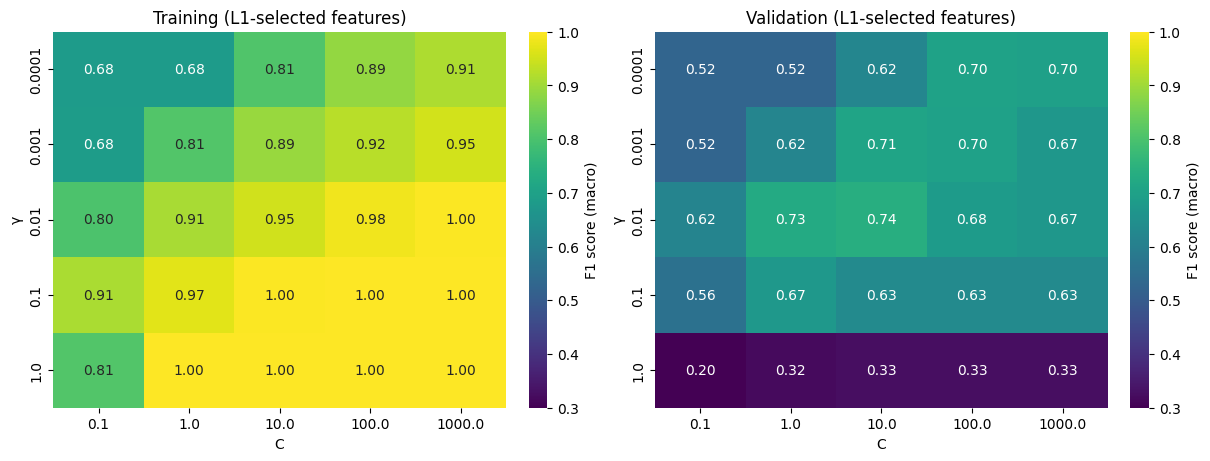

In [10]:
#Heat maps of the training and validation score over C and gamma
best_selection = results.loc[results.mean_test_score.idxmax(), "selection"]
r = results[results.selection == best_selection]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, score, title in zip(axes, ["mean_train_score", "mean_test_score"], ["Training", "Validation"]):
    table = r.pivot_table(index="param_clf__gamma", columns="param_clf__C", values=score)
    sn.heatmap(table, annot=True, fmt=".2f", cmap="viridis", vmin=0.3, vmax=1, ax=ax, cbar_kws={"label": "F1 score (macro)"})
    ax.set_title(f"{title} ({best_selection})")
    ax.set_xlabel("C")
    ax.set_ylabel("γ")
fig.savefig(FIG_DIR / "svm_features_grid.pdf", bbox_inches="tight")
plt.show()

## Task 4 - Nested leave-one-person-out evaluation
- For every person: tune C, γ and the selection step with a LOPO grid search on the other five persons, then test the best model once on the held-out person.
- Calculate and print the accuracy and macro-F1 score (mean ± std over the six persons).
- Plot the accuracy per person and the confusion matrix.

In [11]:
#Nested leave-one-person-out
logo = LeaveOneGroupOut()
y_pred_nested = np.zeros_like(y)
best_params = []

for train_idx, test_idx in logo.split(X, y, groups=persons):
    person = persons[test_idx][0]

    # Inner loop: tune the hyperparameters on the five training persons only
    search = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1)
    search.fit(X[train_idx], y[train_idx], groups=persons[train_idx])

    # Outer loop: test once on the held-out person
    y_pred_nested[test_idx] = search.predict(X[test_idx])
    params = clean(search.best_params_)
    params["select"] = "all" if params["select"] == "passthrough" else "L1"
    best_params.append({"person": person, **params})
    print(f"Person {person} held out -> best parameters: {best_params[-1]}")

scores_nested = lopo_scores(y, y_pred_nested, persons).merge(pd.DataFrame(best_params), on="person")
scores_nested

Person A held out -> best parameters: {'person': 'A', 'C': 1.0, 'gamma': 0.01, 'select': 'L1'}
Person B held out -> best parameters: {'person': 'B', 'C': 100.0, 'gamma': 0.001, 'select': 'L1'}
Person C held out -> best parameters: {'person': 'C', 'C': 100.0, 'gamma': 0.01, 'select': 'all'}
Person D held out -> best parameters: {'person': 'D', 'C': 10.0, 'gamma': 0.01, 'select': 'L1'}
Person E held out -> best parameters: {'person': 'E', 'C': 1000.0, 'gamma': 0.0001, 'select': 'all'}
Person F held out -> best parameters: {'person': 'F', 'C': 10.0, 'gamma': 0.01, 'select': 'L1'}


,person,accuracy,f1_macro,C,gamma,select
0,A,0.76875,0.770605,1.0,0.0100,L1
1,B,0.45625,0.384688,100.0,0.0010,L1
2,C,0.67500,0.665249,100.0,0.0100,all
3,D,0.76875,0.756202,10.0,0.0100,L1
4,E,0.66875,0.659795,1000.0,0.0001,all
5,F,0.82500,0.815545,10.0,0.0100,L1


In [12]:
#Performance metrics
print("Baseline:")
print_scores(scores_base)
print("Tuned (nested LOPO):")
print_scores(scores_nested)

Baseline:
Accuracy: 0.692 ± 0.155
F1 score (macro): 0.685 ± 0.157
Tuned (nested LOPO):
Accuracy: 0.694 ± 0.131
F1 score (macro): 0.675 ± 0.155


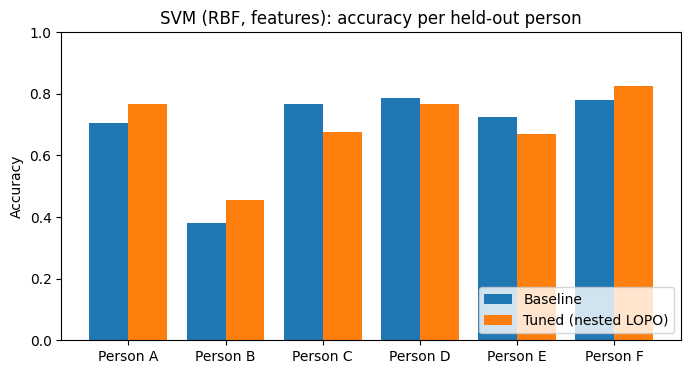

In [13]:
#Accuracy per held-out person: baseline vs tuned model
x = np.arange(len(scores_nested))

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, scores_base.accuracy, width=0.4, label="Baseline")
plt.bar(x + 0.2, scores_nested.accuracy, width=0.4, label="Tuned (nested LOPO)")
plt.xticks(x, ["Person " + p for p in scores_nested.person])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("SVM (RBF, features): accuracy per held-out person")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "svm_features_per_person.pdf", bbox_inches="tight")
plt.show()

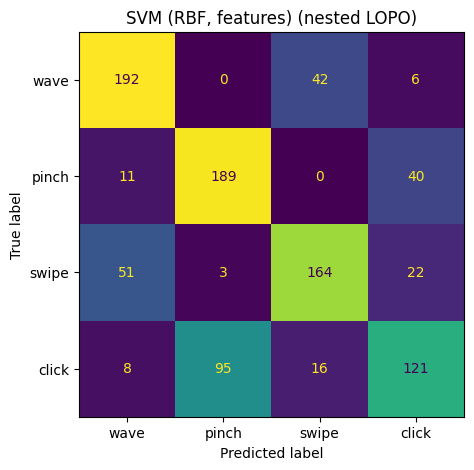

In [14]:
#Confusion matrix of the tuned model, summed over the six held-out persons
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y, y_pred_nested, display_labels=gestures, ax=ax, colorbar=False)
ax.set_title("SVM (RBF, features) (nested LOPO)")
fig.savefig(FIG_DIR / "svm_features_confusion_matrix.pdf", bbox_inches="tight")
plt.show()

## Task 5 - Number of support vectors
The support vectors are the training samples on or inside the margin. Many support vectors mean a complex decision boundary.

- Train the SVM with the best parameters of Task 3 on all data and print the number of support vectors per gesture.

In [15]:
#Support vectors of the final model
final_svm = search_all.best_estimator_
n_sv = final_svm.named_steps["clf"].n_support_
print("Support vectors per gesture: " + str({str(g): int(n) for g, n in zip(gestures, n_sv)}))
print(f"Total: {n_sv.sum()} of {len(y)} samples")

Support vectors per gesture: {'wave': 62, 'pinch': 100, 'swipe': 73, 'click': 128}
Total: 363 of 960 samples


## Task 6 - Comparison with a random split
The data exploration notebook (`wicos.ipynb`) uses a random, stratified 80/20 split. To show why we validate per person, the same model is tuned with the random 5-fold cross-validation of that notebook and tested on its random 20% test set.

- Tune the model with the predefined random folds (`cv_fold`) on the training set.
- Test it on the random test set and compare the score with the LOPO result.

In [16]:
#Random split: tune with the random 5-fold CV, test on the random 20% test set
idx_train, idx_test, cv_fold = data["idx_train"], data["idx_test"], data["cv_fold"]

search_rs = GridSearchCV(clf, param_grid, cv=PredefinedSplit(cv_fold[idx_train]), scoring="f1_macro", n_jobs=-1)
search_rs.fit(X[idx_train], y[idx_train])
y_pred_rs = search_rs.predict(X[idx_test])

accuracy_rs = accuracy_score(y[idx_test], y_pred_rs)
f1_rs = f1_score(y[idx_test], y_pred_rs, average="macro")
print("Best parameters: " + str(clean(search_rs.best_params_)))
print("Accuracy: " + str(round(accuracy_rs, 3)))
print("F1 score (macro): " + str(round(f1_rs, 3)))

Best parameters: {'C': 1.0, 'gamma': 0.1, 'select': 'passthrough'}
Accuracy: 0.922
F1 score (macro): 0.922


In [17]:
#Random split vs leave-one-person-out
comparison = pd.DataFrame({
    "Accuracy": [accuracy_rs, scores_nested.accuracy.mean()],
    "F1 score (macro)": [f1_rs, scores_nested.f1_macro.mean()],
}, index=["Random 80/20 split", "Leave-one-person-out (mean)"])
comparison.round(3)

,Accuracy,F1 score (macro)
Random 80/20 split,0.922,0.922
Leave-one-person-out (mean),0.694,0.675


## Task 7 - Save the results
The per-person scores and a one-line summary are saved in `results/`, so all models can be compared in one table.

In [18]:
#Save the results
scores_nested.to_csv(RES_DIR / "svm_rbf_features_lopo.csv", index=False)

summary = pd.DataFrame([{
    "model": "SVM RBF (features)",
    "lopo_accuracy_mean": scores_nested.accuracy.mean(),
    "lopo_accuracy_std": scores_nested.accuracy.std(),
    "lopo_f1_mean": scores_nested.f1_macro.mean(),
    "lopo_f1_std": scores_nested.f1_macro.std(),
    "random_split_accuracy": accuracy_rs,
    "random_split_f1": f1_rs,
}])
summary.to_csv(RES_DIR / "svm_rbf_features_summary.csv", index=False)
summary.round(3)

,model,lopo_accuracy_mean,lopo_accuracy_std,lopo_f1_mean,lopo_f1_std,random_split_accuracy,random_split_f1
0,SVM RBF (features),0.694,0.131,0.675,0.155,0.922,0.922
